In [2]:
import keras

In [3]:
from keras.datasets import imdb
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=1000)

In [11]:
# بررسی ساختار دیکشنری کلمات
d_view = [(v, k) for k, v in imdb.get_word_index().items()]
d_view.sort()
for v, k in d_view[:20]:
    print("{}:\t{}".format(k, v))
for v, k in d_view[-20:]:
    print("{}:\t{}".format(k, v))

the:	1
and:	2
a:	3
of:	4
to:	5
is:	6
br:	7
in:	8
it:	9
i:	10
this:	11
that:	12
was:	13
as:	14
for:	15
with:	16
movie:	17
but:	18
film:	19
on:	20
percival:	88565
lubricated:	88566
heralding:	88567
baywatch':	88568
odilon:	88569
'solve':	88570
guard's:	88571
nemesis':	88572
airsoft:	88573
urrrghhh:	88574
ev:	88575
chicatillo:	88576
transacting:	88577
sics:	88578
wheelers:	88579
pipe's:	88580
copywrite:	88581
artbox:	88582
voorhees':	88583
'l':	88584


In [12]:
print(train_data[0])
print(train_labels[0])

[1, 14, 22, 16, 43, 530, 973, 2, 2, 65, 458, 2, 66, 2, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 2, 2, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2, 19, 14, 22, 4, 2, 2, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 2, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2, 2, 16, 480, 66, 2, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 2, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 2, 15, 256, 4, 2, 7, 2, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 2, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2, 56, 26, 141, 6, 194, 2, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 2, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 2, 88, 12, 16, 283, 5, 16, 2, 113, 103, 32, 15, 16, 2, 19, 178, 32]
1


In [13]:
import numpy as np
np.array([len(d) for d in train_data])

array([218, 189, 141, ..., 184, 150, 153], shape=(25000,))

In [14]:
def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)

print(x_train.shape)
print(x_train[0])

(25000, 10000)
[0. 1. 1. ... 0. 0. 0.]


In [15]:
y_train = np.asarray(train_labels).astype('float32')
y_test = np.asarray(test_labels).astype('float32')

In [16]:
model = keras.models.Sequential()
model.add(keras.layers.Dense(16, activation='relu', input_shape=(10000,)))
model.add(keras.layers.Dense(16, activation='relu'))
model.add(keras.layers.Dense(1, activation='sigmoid'))

model.compile(optimizer='sgd',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train,
                    validation_data=(x_test, y_test),
                    epochs=100,
                    batch_size=512)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 108ms/step - accuracy: 0.5157 - loss: 0.6920 - val_accuracy: 0.5450 - val_loss: 0.6894
Epoch 2/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.5877 - loss: 0.6847 - val_accuracy: 0.6157 - val_loss: 0.6795
Epoch 3/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.6564 - loss: 0.6698 - val_accuracy: 0.6896 - val_loss: 0.6610
Epoch 4/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.7250 - loss: 0.6474 - val_accuracy: 0.7334 - val_loss: 0.6368
Epoch 5/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.7598 - loss: 0.6214 - val_accuracy: 0.7587 - val_loss: 0.6107
Epoch 6/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.7786 - loss: 0.5945 - val_accuracy: 0.7793 - val_loss: 0.5843
Epoch 7/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.7920 - loss: 0.5675 - val_accuracy: 0.7894 - val_loss: 0.5580
Epoch 8/100
49/49 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - accuracy: 0.7999 - loss: 0.5407 - val_accuracy: 0

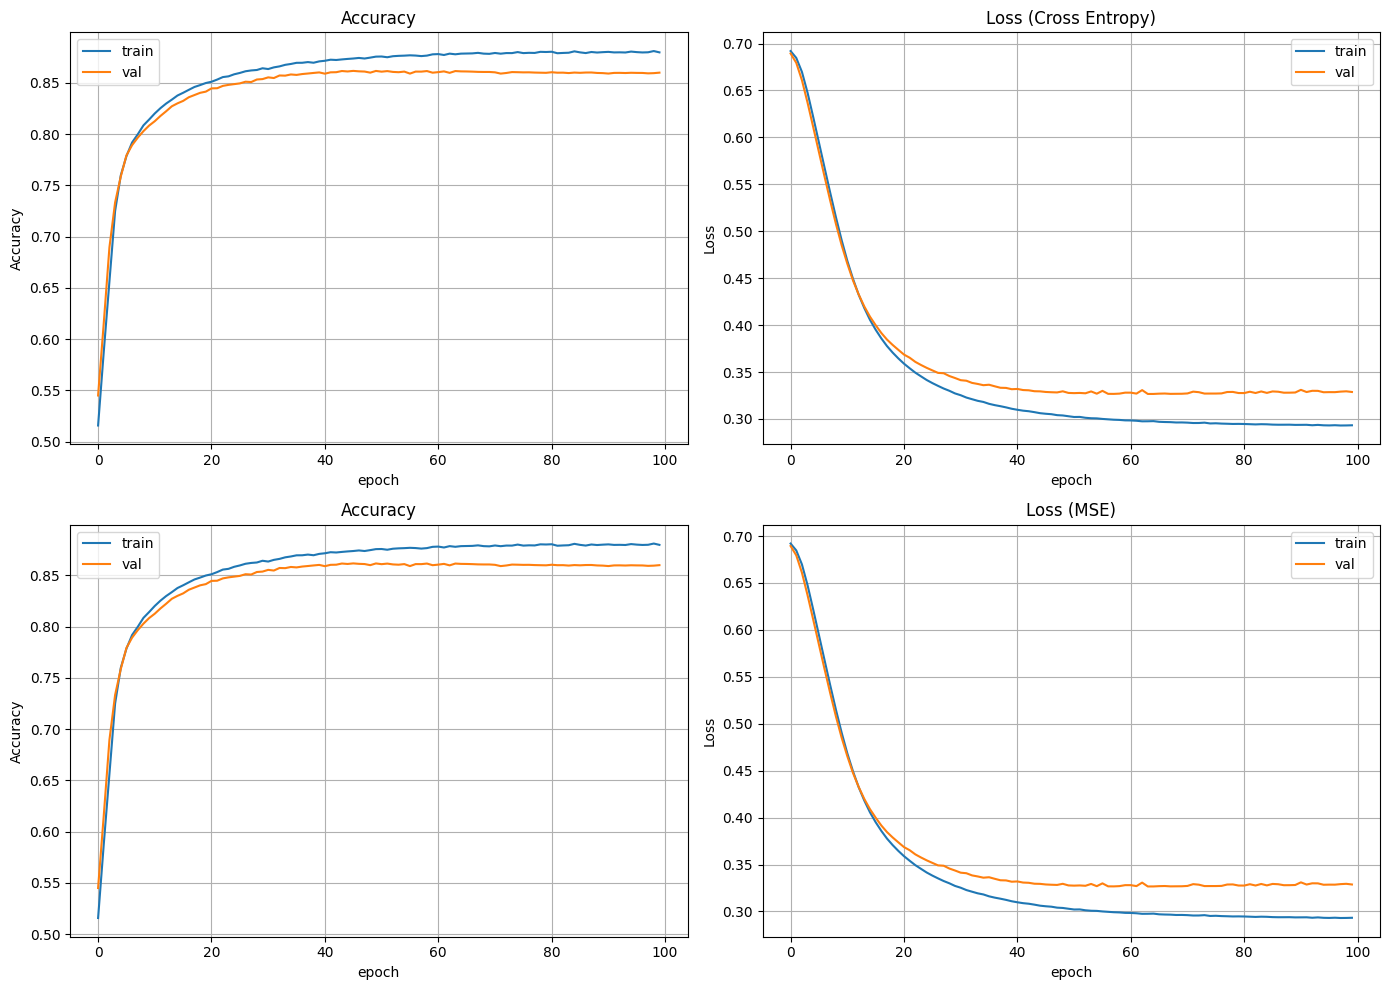

In [20]:
import matplotlib.pyplot as plt

# تنظیم اندازه کلی نمودارها
plt.figure(figsize=(14, 10))

# نمودار 1: دقت (Accuracy)
plt.subplot(2, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# نمودار 2: خطا (Loss - Cross Entropy)
plt.subplot(2, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss (Cross Entropy)')
plt.xlabel('epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# نمودار 3: دقت (تکرار برای مقایسه)
plt.subplot(2, 2, 3)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title('Accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# نمودار 4: خطا (Loss - MSE)
plt.subplot(2, 2, 4)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title('Loss (MSE)')
plt.xlabel('epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# نمایش نمودارها
plt.tight_layout()
plt.show()

In [21]:
import keras
from keras import layers
import matplotlib.pyplot as plt

# --- 1. ساخت و آموزش مدل با بهینه‌ساز SGD ---
model_sgd = keras.models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(10000,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_sgd.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])
history_sgd = model_sgd.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=100, batch_size=512, verbose=0)

# --- 2. ساخت و آموزش مدل با بهینه‌ساز Adam ---
model_adam = keras.models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(10000,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model_adam.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history_adam = model_adam.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=20, batch_size=512, verbose=0)

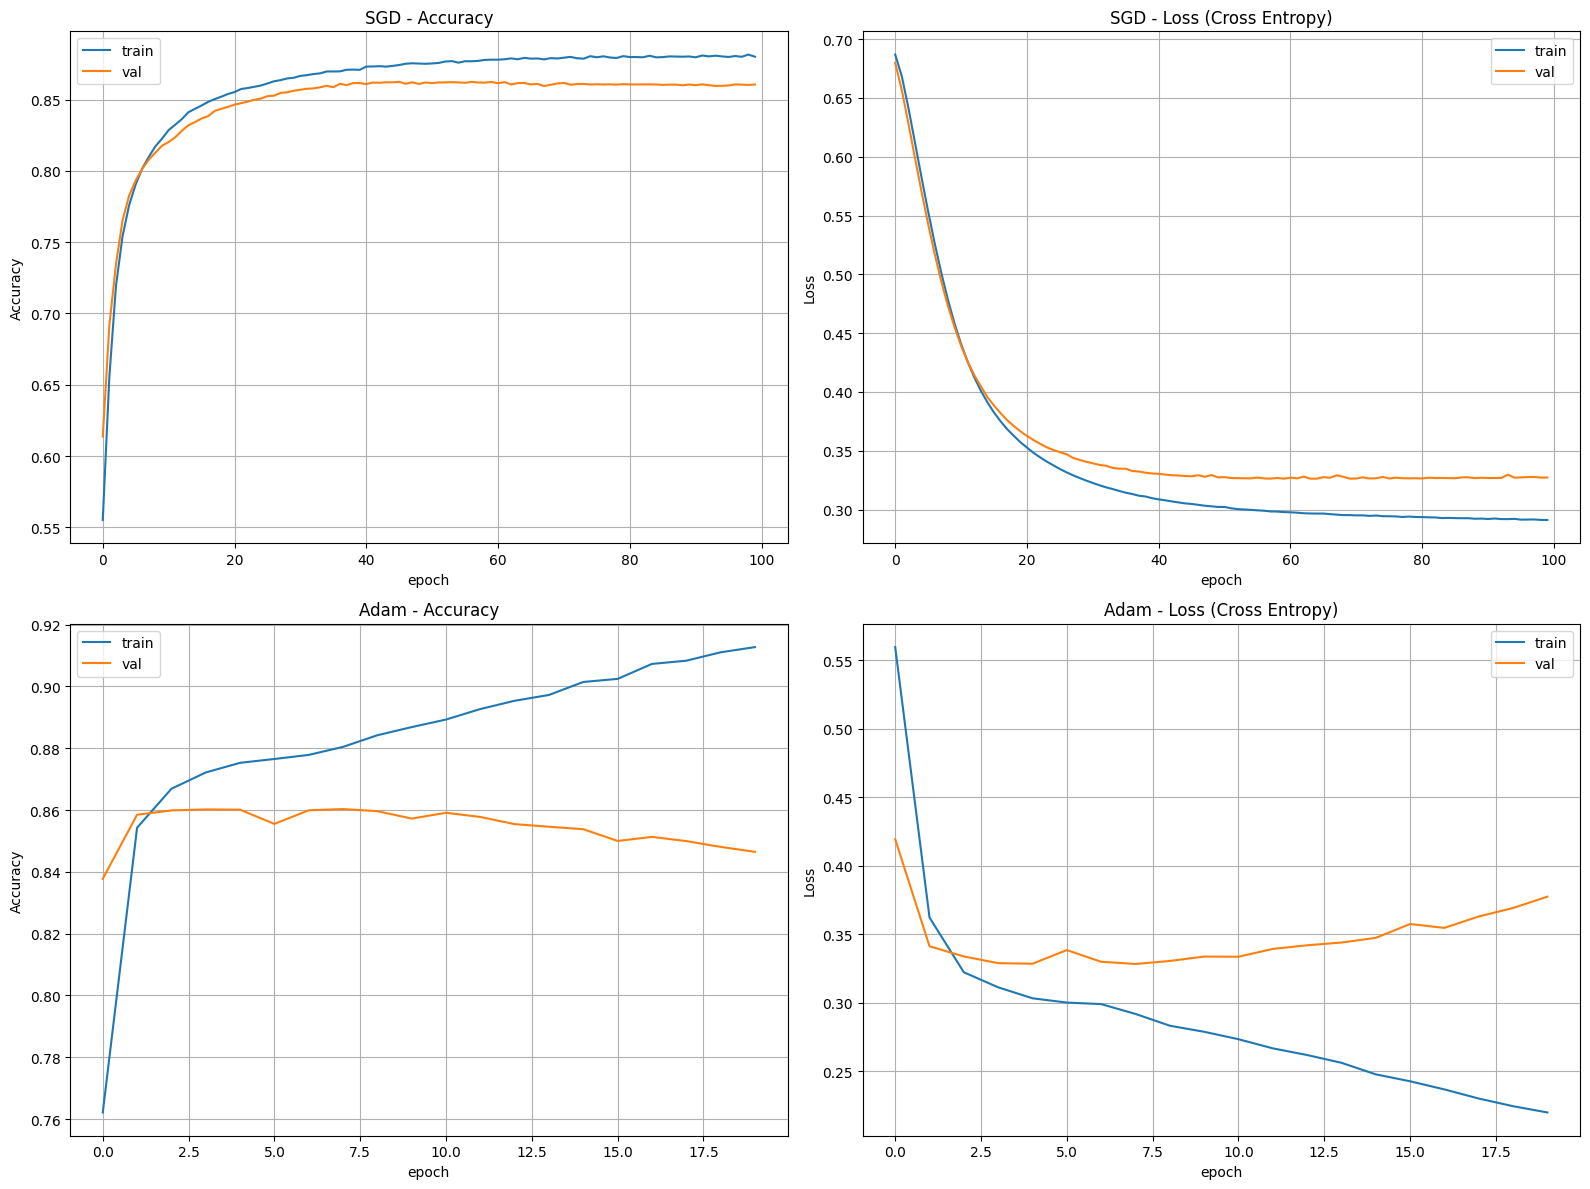

In [22]:
plt.figure(figsize=(16, 12))

# --- نمودارهای SGD (ردیف بالا) ---
# دقت SGD
plt.subplot(2, 2, 1)
plt.plot(history_sgd.history['accuracy'], label='train')
plt.plot(history_sgd.history['val_accuracy'], label='val')
plt.title('SGD - Accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# خطای SGD
plt.subplot(2, 2, 2)
plt.plot(history_sgd.history['loss'], label='train')
plt.plot(history_sgd.history['val_loss'], label='val')
plt.title('SGD - Loss (Cross Entropy)')
plt.xlabel('epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# --- نمودارهای Adam (ردیف پایین) ---
# دقت Adam
plt.subplot(2, 2, 3)
plt.plot(history_adam.history['accuracy'], label='train')
plt.plot(history_adam.history['val_accuracy'], label='val')
plt.title('Adam - Accuracy')
plt.xlabel('epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# خطای Adam
plt.subplot(2, 2, 4)
plt.plot(history_adam.history['loss'], label='train')
plt.plot(history_adam.history['val_loss'], label='val')
plt.title('Adam - Loss (Cross Entropy)')
plt.xlabel('epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [1]:
import gradio as gr
import numpy as np
from tensorflow import keras
from keras.datasets import imdb
from keras import layers

# 1. Load and prepare data
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(num_words=10000)

def vectorize_sequences(sequences, dimension=10000):
    results = np.zeros((len(sequences), dimension))
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype('float32')
y_test = np.asarray(test_labels).astype('float32')

# 2. Build and train model
model = keras.models.Sequential([
    layers.Dense(16, activation='relu', input_shape=(10000,)),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=5, batch_size=512, verbose=0)

# 3. Prediction function
def predict_review(text):
    # Simple tokenization (for demo purposes)
    words = text.lower().split()
    word_index = imdb.get_word_index()
    sequence = [word_index.get(w, 0) + 3 for w in words if word_index.get(w, 0) + 3 < 10000]
    if not sequence:
        return {"Positive": 0.0, "Negative": 0.0}
    vec = vectorize_sequences([sequence])
    pred = model.predict(vec)[0][0]
    return {"Positive": float(pred), "Negative": float(1 - pred)}

# 4. Gradio Interface
interface = gr.Interface(
    fn=predict_review,
    inputs=gr.Textbox(lines=5, placeholder="Enter a movie review here..."),
    outputs=gr.Label(num_top_classes=2),
    title="IMDB Movie Review Sentiment Classifier",
    description="Enter a movie review to see if the model predicts it as positive or negative."
)

interface.launch()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b541c978b9d78cfec1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
